# 03 Energy intensity

Energy intensity is compressor power per Nm3 of on-spec N2 sent to the header (kWh/Nm3). The feed air compressor is almost all of a cryogenic package's power draw, so this one ratio is the package's energy bill per unit of product.

Questions:

1. Which package burns the most energy per Nm3?
2. Why: design, fouling, the weather, or something else?
3. What is that costing in naira, and what would fix it?
4. Does energy intensity move before a trip?

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from plant_style import (apply_style, save, load, PACKAGE_COLOURS, CAUSE_COLOURS, ALERT, INK_2,
                         MODE_NAMES, RAW, PROCESSED, SPLIT_VALID, SPLIT_TEST)

apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

from sklearn.linear_model import LinearRegression

hourly = load("hourly_process_data")
downtime = load("downtime_events")
daily = load("daily_package_summary")

# Steady running hours with product going to the header. Startup hours and
# off-spec hours are left out; they are covered by OEE quality in notebook 02.
run = hourly[(hourly.operating_state == "RUN") & (hourly.product_n2_flow_nm3h > 0)].dropna(
    subset=["feed_air_compressor_power_kw", "product_n2_flow_nm3h"]).copy()
run["energy_intensity"] = run.feed_air_compressor_power_kw / run.product_n2_flow_nm3h
run["specific_air_power"] = run.feed_air_compressor_power_kw / run.feed_air_flow_nm3h
run["approach_temp"] = run.feed_air_discharge_temp_degC - run.cooling_water_supply_temp_degC
run["month"] = run.timestamp.dt.to_period("M").dt.to_timestamp()
print(f"{len(run):,} steady running hours")

48,919 steady running hours


## Which package is worst?

In [2]:
summary = run.groupby("package_id").agg(
    energy_intensity_kwh_nm3=("energy_intensity", "median"),
    specific_air_power_kwh_nm3=("specific_air_power", "median"),
    aftercooler_approach_degC=("approach_temp", "median"),
    compressor_power_kw=("feed_air_compressor_power_kw", "median"),
)
summary["vs_NGU-A_pct"] = 100 * (summary.energy_intensity_kwh_nm3 / summary.loc["NGU-A", "energy_intensity_kwh_nm3"] - 1)
summary.round(3)

,energy_intensity_kwh_nm3,specific_air_power_kwh_nm3,aftercooler_approach_degC,compressor_power_kw,vs_NGU-A_pct
package_id,,,,,
NGU-A,0.314,0.160,8.94,304.2,0.000
NGU-B,0.318,0.162,9.15,308.2,1.255
NGU-C,0.348,0.177,12.12,336.1,10.601


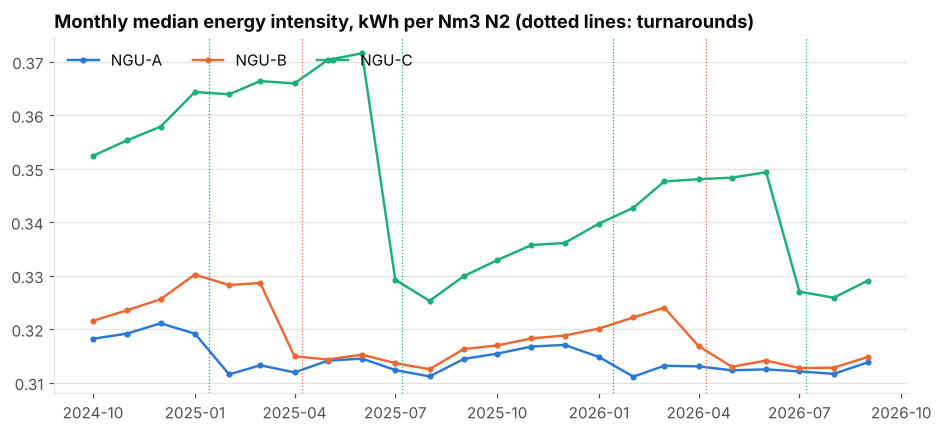

In [3]:
turnarounds = downtime[downtime.failure_mode == "turnaround"]
m = run.groupby(["month", "package_id"]).energy_intensity.median().reset_index()

fig, ax = plt.subplots()
for pkg, g in m.groupby("package_id"):
    ax.plot(g.month, g.energy_intensity, color=PACKAGE_COLOURS[pkg], label=pkg, marker="o", ms=3)
for _, t in turnarounds.iterrows():
    ax.axvline(t.trip_time, color=PACKAGE_COLOURS[t.package_id], lw=0.8, ls=":")
ax.set_title("Monthly median energy intensity, kWh per Nm3 N2 (dotted lines: turnarounds)")
ax.legend(ncol=3, loc="upper left")
save(fig, "03_energy_intensity_monthly")
plt.show()

NGU-C is the worst every single month. Its line is also a sawtooth: it climbs through the year and drops back after each turnaround in July. NGU-A and NGU-B do the same, but much more gently. A rising line that resets at turnaround points to fouling that the turnaround cleans out.

## Why: fouling, design, or the weather?

Days since the last turnaround come from the maintenance log. For the months before the first turnaround in the data, the previous turnaround is taken as one year earlier, per the annual maintenance plan.

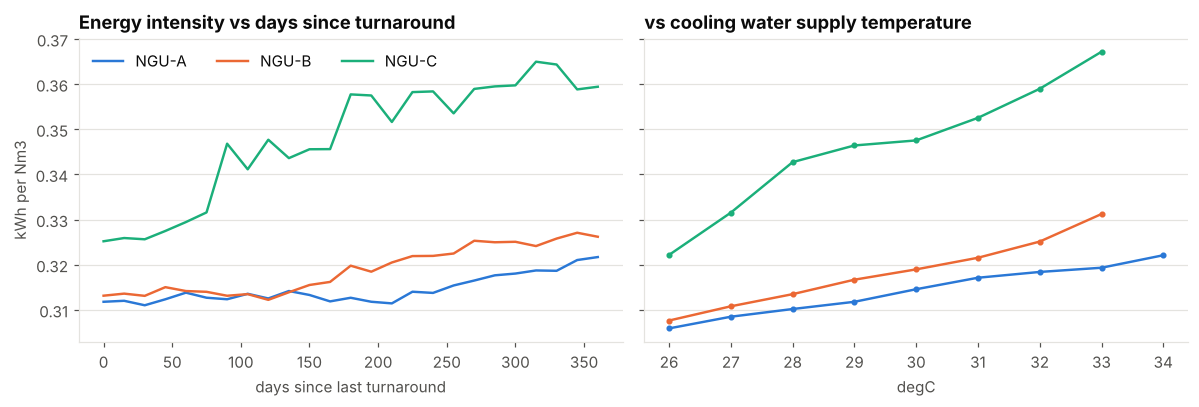

In [4]:
def days_since_turnaround(df):
    out = pd.Series(np.nan, index=df.index)
    for pkg, g in df.groupby("package_id"):
        ta = np.sort(turnarounds.loc[turnarounds.package_id == pkg, "trip_time"].to_numpy())
        ta = np.concatenate([[ta[0] - np.timedelta64(365, "D")], ta])
        idx = np.searchsorted(ta, g.timestamp.to_numpy(), side="right") - 1
        out[g.index] = (g.timestamp.to_numpy() - ta[idx]) / np.timedelta64(1, "D")
    return out

run["days_since_ta"] = days_since_turnaround(run)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for pkg, g in run.groupby("package_id"):
    b = g.groupby((g.days_since_ta // 15) * 15).energy_intensity.median()
    axes[0].plot(b.index, b.values, color=PACKAGE_COLOURS[pkg], label=pkg)
    c = g.groupby(g.cooling_water_supply_temp_degC.round(0)).energy_intensity.median()
    c = c[g.groupby(g.cooling_water_supply_temp_degC.round(0)).size() > 100]
    axes[1].plot(c.index, c.values, color=PACKAGE_COLOURS[pkg], label=pkg, marker="o", ms=3)
axes[0].set_title("Energy intensity vs days since turnaround")
axes[0].set_xlabel("days since last turnaround")
axes[0].set_ylabel("kWh per Nm3")
axes[1].set_title("vs cooling water supply temperature")
axes[1].set_xlabel("degC")
axes[0].legend(ncol=3, loc="upper left")
fig.tight_layout()
save(fig, "03_drivers")
plt.show()

Careful with the right-hand chart. NGU-C looks far more sensitive to cooling water temperature, but its turnaround is in July, so its hot dry-season months (February, March) fall eight months into its fouling cycle. Weather and fouling move together for NGU-C, and a one-variable chart cannot pull them apart.

A linear model can. Each package gets its own intercept and its own fouling slope; cooling water temperature and load are shared across packages, on the assumption that hot water costs every compressor about the same.

In [5]:
X = pd.DataFrame(index=run.index)
for pkg in ["NGU-B", "NGU-C"]:
    X[f"is_{pkg}"] = (run.package_id == pkg).astype(float)
for pkg in ["NGU-A", "NGU-B", "NGU-C"]:
    X[f"days_since_ta_{pkg}"] = run.days_since_ta * (run.package_id == pkg)
X["cw_temp_above_30"] = run.cooling_water_supply_temp_degC - 30
X["load_pct_of_design"] = run.product_n2_flow_nm3h / 10
y = run.energy_intensity

model = LinearRegression().fit(X, y)
coefs = pd.Series(model.coef_, index=X.columns)
print(f"R2 = {model.score(X, y):.3f}, intercept {model.intercept_:.4f} kWh/Nm3")
print()
print("Per-year fouling penalty, kWh/Nm3:")
for pkg in ["NGU-A", "NGU-B", "NGU-C"]:
    print(f"  {pkg}: {365 * coefs[f'days_since_ta_{pkg}']:.4f}")
print(f"Built-in gap vs NGU-A at zero fouling: NGU-B {coefs['is_NGU-B']:+.4f}, NGU-C {coefs['is_NGU-C']:+.4f}")
print(f"Each 1 degC of cooling water: {coefs['cw_temp_above_30']:+.4f} kWh/Nm3")

R2 = 0.865, intercept 0.3238 kWh/Nm3

Per-year fouling penalty, kWh/Nm3:
  NGU-A: 0.0109
  NGU-B: 0.0146
  NGU-C: 0.0362
Built-in gap vs NGU-A at zero fouling: NGU-B +0.0031, NGU-C +0.0211
Each 1 degC of cooling water: +0.0027 kWh/Nm3


In [6]:
# Split NGU-C's average gap to NGU-A into its parts.
mean_days = run.groupby("package_id").days_since_ta.mean()
fouling_gap = (coefs["days_since_ta_NGU-C"] * mean_days["NGU-C"] - coefs["days_since_ta_NGU-A"] * mean_days["NGU-A"])
base_gap = coefs["is_NGU-C"]
total_gap = summary.loc["NGU-C", "energy_intensity_kwh_nm3"] - summary.loc["NGU-A", "energy_intensity_kwh_nm3"]
gap = pd.Series({"built-in (compressor efficiency)": base_gap, "intercooler fouling": fouling_gap})
gap["other"] = total_gap - gap.sum()
(gap / total_gap * 100).round(0).rename("share of NGU-C gap, %")

built-in (compressor efficiency)    63.0
intercooler fouling                 39.0
other                               -2.0
Name: share of NGU-C gap, %, dtype: float64

Two things make NGU-C expensive. The larger part is built in: at the same fouling, weather and load, NGU-C uses more power for the same air. That points at the compressor itself, worn impellers or internal recirculation, and it will not clear without a compressor overhaul. The rest is intercooler fouling, which NGU-C picks up close to three times faster than NGU-A. Once fouling is separated out, hot cooling water costs about 0.003 kWh/Nm3 per degC on every package; it raises everyone's bill in the dry season but does not explain NGU-C's gap.

## Running hours vs energy consumption

The same story at daily level: for a full day of running, NGU-C draws more kWh.

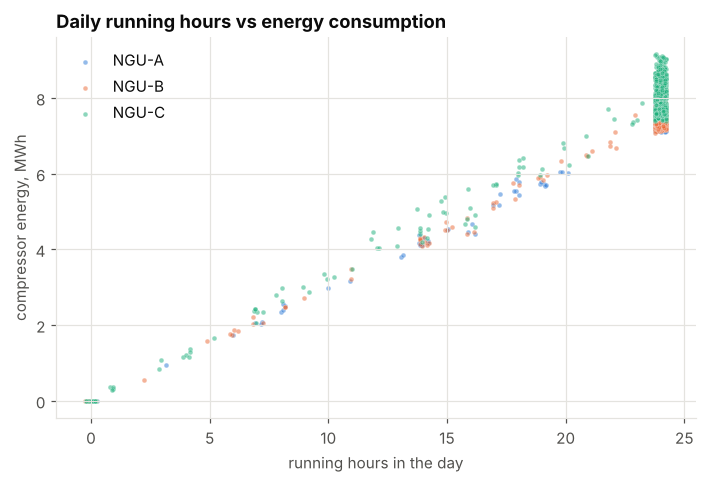

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for pkg, g in daily.groupby("package_id"):
    ax.scatter(g.running_hours + np.random.default_rng(1).uniform(-0.25, 0.25, len(g)),
               g.power_consumption_kwh / 1000, s=10, alpha=0.5, color=PACKAGE_COLOURS[pkg], label=pkg,
               edgecolor="white", linewidth=0.3)
ax.set_xlabel("running hours in the day")
ax.set_ylabel("compressor energy, MWh")
ax.set_title("Daily running hours vs energy consumption")
ax.legend(loc="upper left")
ax.grid(axis="x")
save(fig, "03_running_hours_vs_energy")
plt.show()

## What it costs

Power for the unit comes from the complex's gas-fired captive plant. The cost per kWh below is an assumption for illustration, not a quoted tariff. Change it to your own figure and the numbers follow.

In [8]:
NGN_PER_KWH = 150  # assumption: captive gas-fired power, naira per kWh

prod_c = run.loc[run.package_id == "NGU-C", "product_n2_flow_nm3h"].sum()  # Nm3 over two years (hourly rows)
years = 2
excess_kwh_yr = total_gap * prod_c / years
fouling_kwh_yr = fouling_gap * prod_c / years
# A mid-year intercooler clean halves NGU-C's average days since cleaning.
midyear_kwh_yr = coefs["days_since_ta_NGU-C"] * mean_days["NGU-C"] / 2 * prod_c / years

print(f"NGU-C excess energy vs NGU-A: {excess_kwh_yr/1e3:,.0f} MWh/yr, about N{excess_kwh_yr*NGN_PER_KWH/1e6:,.1f} million a year")
print(f"  of which intercooler fouling: {fouling_kwh_yr/1e3:,.0f} MWh/yr, about N{fouling_kwh_yr*NGN_PER_KWH/1e6:,.1f} million")
print(f"A mid-year intercooler clean on NGU-C would save about {midyear_kwh_yr/1e3:,.0f} MWh/yr, "
      f"N{midyear_kwh_yr*NGN_PER_KWH/1e6:,.1f} million a year (estimate)")

NGU-C excess energy vs NGU-A: 257 MWh/yr, about N38.5 million a year
  of which intercooler fouling: 99 MWh/yr, about N14.9 million
A mid-year intercooler clean on NGU-C would save about 71 MWh/yr, N10.6 million a year (estimate)


## Does energy intensity move before a trip?

For each unplanned trip, compare energy intensity in the hours before it with that package's median over the 30 days before the fault window. Hours with no product to the header (off-spec O2 near the end of a PPU breakthrough) are left out, since intensity is undefined there.

In [9]:
windows = [(72, 48), (48, 24), (24, 12), (12, 0)]
rows = []
for _, tr in downtime[downtime.event_type == "Unplanned"].iterrows():
    g = run[run.package_id == tr.package_id]
    base = g[(g.timestamp < tr.trip_time - pd.Timedelta(hours=96)) &
             (g.timestamp >= tr.trip_time - pd.Timedelta(days=30))].energy_intensity.median()
    for a, b in windows:
        w = g[(g.timestamp >= tr.trip_time - pd.Timedelta(hours=a)) &
              (g.timestamp < tr.trip_time - pd.Timedelta(hours=b))].energy_intensity
        rows.append(dict(mode=MODE_NAMES[tr.failure_mode], window=f"{a} to {b} h", change_pct=100 * (w.median() / base - 1)))
pre = pd.DataFrame(rows)
pre_table = pre.pivot_table(index="mode", columns="window", values="change_pct", aggfunc="median")
pre_table = pre_table[[f"{a} to {b} h" for a, b in windows]].round(1)
pre_table["trips"] = pre.groupby("mode").size() // len(windows)
pre_table

window,72 to 48 h,48 to 24 h,24 to 12 h,12 to 0 h,trips
mode,,,,,
Compressor vibration,0.2,0.3,2.6,7.6,15
Cooling water loss,0.0,0.1,-0.5,1.0,6
Coupling failure,0.1,0.3,1.0,-0.3,4
Expander bearing,0.8,1.0,3.7,11.8,12
Grid power dip,0.4,-0.3,-0.2,-0.7,18
Motor relay trip,0.3,0.1,0.2,-0.2,8
PPU breakthrough,-0.2,0.2,0.1,-0.0,18
PPU valve failure,0.5,-0.1,-0.5,1.3,3


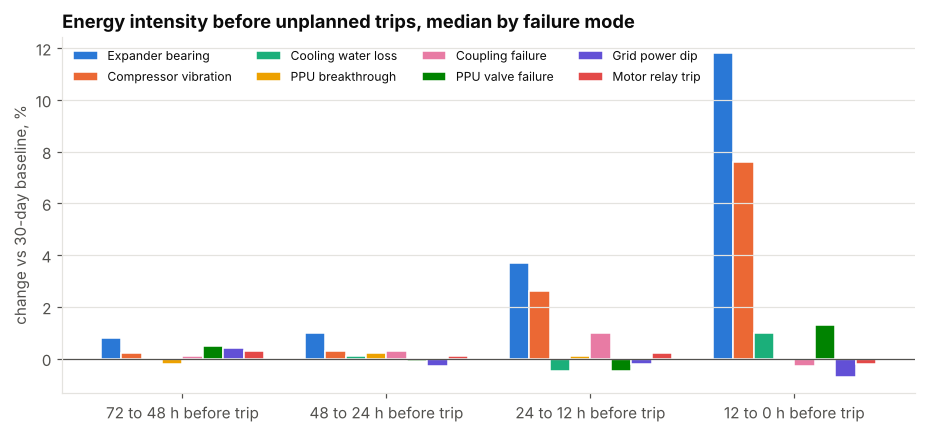

In [10]:
fig, ax = plt.subplots()
order = ["Expander bearing", "Compressor vibration", "Cooling water loss", "PPU breakthrough",
         "Coupling failure", "PPU valve failure", "Grid power dip", "Motor relay trip"]
x = np.arange(len(windows))
width = 0.1
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
for i, mode in enumerate(order):
    vals = pre_table.loc[mode, [f"{a} to {b} h" for a, b in windows]].to_numpy()
    ax.bar(x + (i - 3.5) * width, vals, width, color=palette[i], label=mode, edgecolor="white", linewidth=1)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(x, [f"{a} to {b} h before trip" for a, b in windows])
ax.set_ylabel("change vs 30-day baseline, %")
ax.set_title("Energy intensity before unplanned trips, median by failure mode")
ax.legend(ncol=4, loc="upper left", fontsize=8)
save(fig, "03_pre_trip_energy_intensity")
plt.show()

## Findings

In [11]:
bearing = pre_table.loc["Expander bearing"]
comp = pre_table.loc["Compressor vibration"]
print(f"1. NGU-C runs at {summary.loc['NGU-C', 'energy_intensity_kwh_nm3']:.3f} kWh/Nm3, "
      f"{summary.loc['NGU-C', 'vs_NGU-A_pct']:.0f}% above NGU-A.")
print(f"2. About {100*base_gap/total_gap:.0f}% of that gap is the compressor itself; about {100*fouling_gap/total_gap:.0f}% is intercooler fouling.")
print(f"3. NGU-C's excess costs about N{excess_kwh_yr*NGN_PER_KWH/1e6:,.0f} million a year at N{NGN_PER_KWH}/kWh. "
      f"A mid-year intercooler clean would recover about N{midyear_kwh_yr*NGN_PER_KWH/1e6:,.0f} million of it.")
print(f"4. Energy intensity rises before mechanical trips: expander bearing {bearing['24 to 12 h']:+.0f}% at 24 to 12 h "
      f"and {bearing['12 to 0 h']:+.0f}% in the last 12 h; compressor vibration {comp['24 to 12 h']:+.0f}% and {comp['12 to 0 h']:+.0f}%. "
      f"Sudden failures show nothing, and neither does a PPU breakthrough, which hits product purity, not power.")

1. NGU-C runs at 0.348 kWh/Nm3, 11% above NGU-A.
2. About 63% of that gap is the compressor itself; about 39% is intercooler fouling.
3. NGU-C's excess costs about N39 million a year at N150/kWh. A mid-year intercooler clean would recover about N11 million of it.
4. Energy intensity rises before mechanical trips: expander bearing +4% at 24 to 12 h and +12% in the last 12 h; compressor vibration +3% and +8%. Sudden failures show nothing, and neither does a PPU breakthrough, which hits product purity, not power.
